# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Leann Vo, Arya Kumar, Ekamjot Singh

**Date:** 11/16/2026

(299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pr

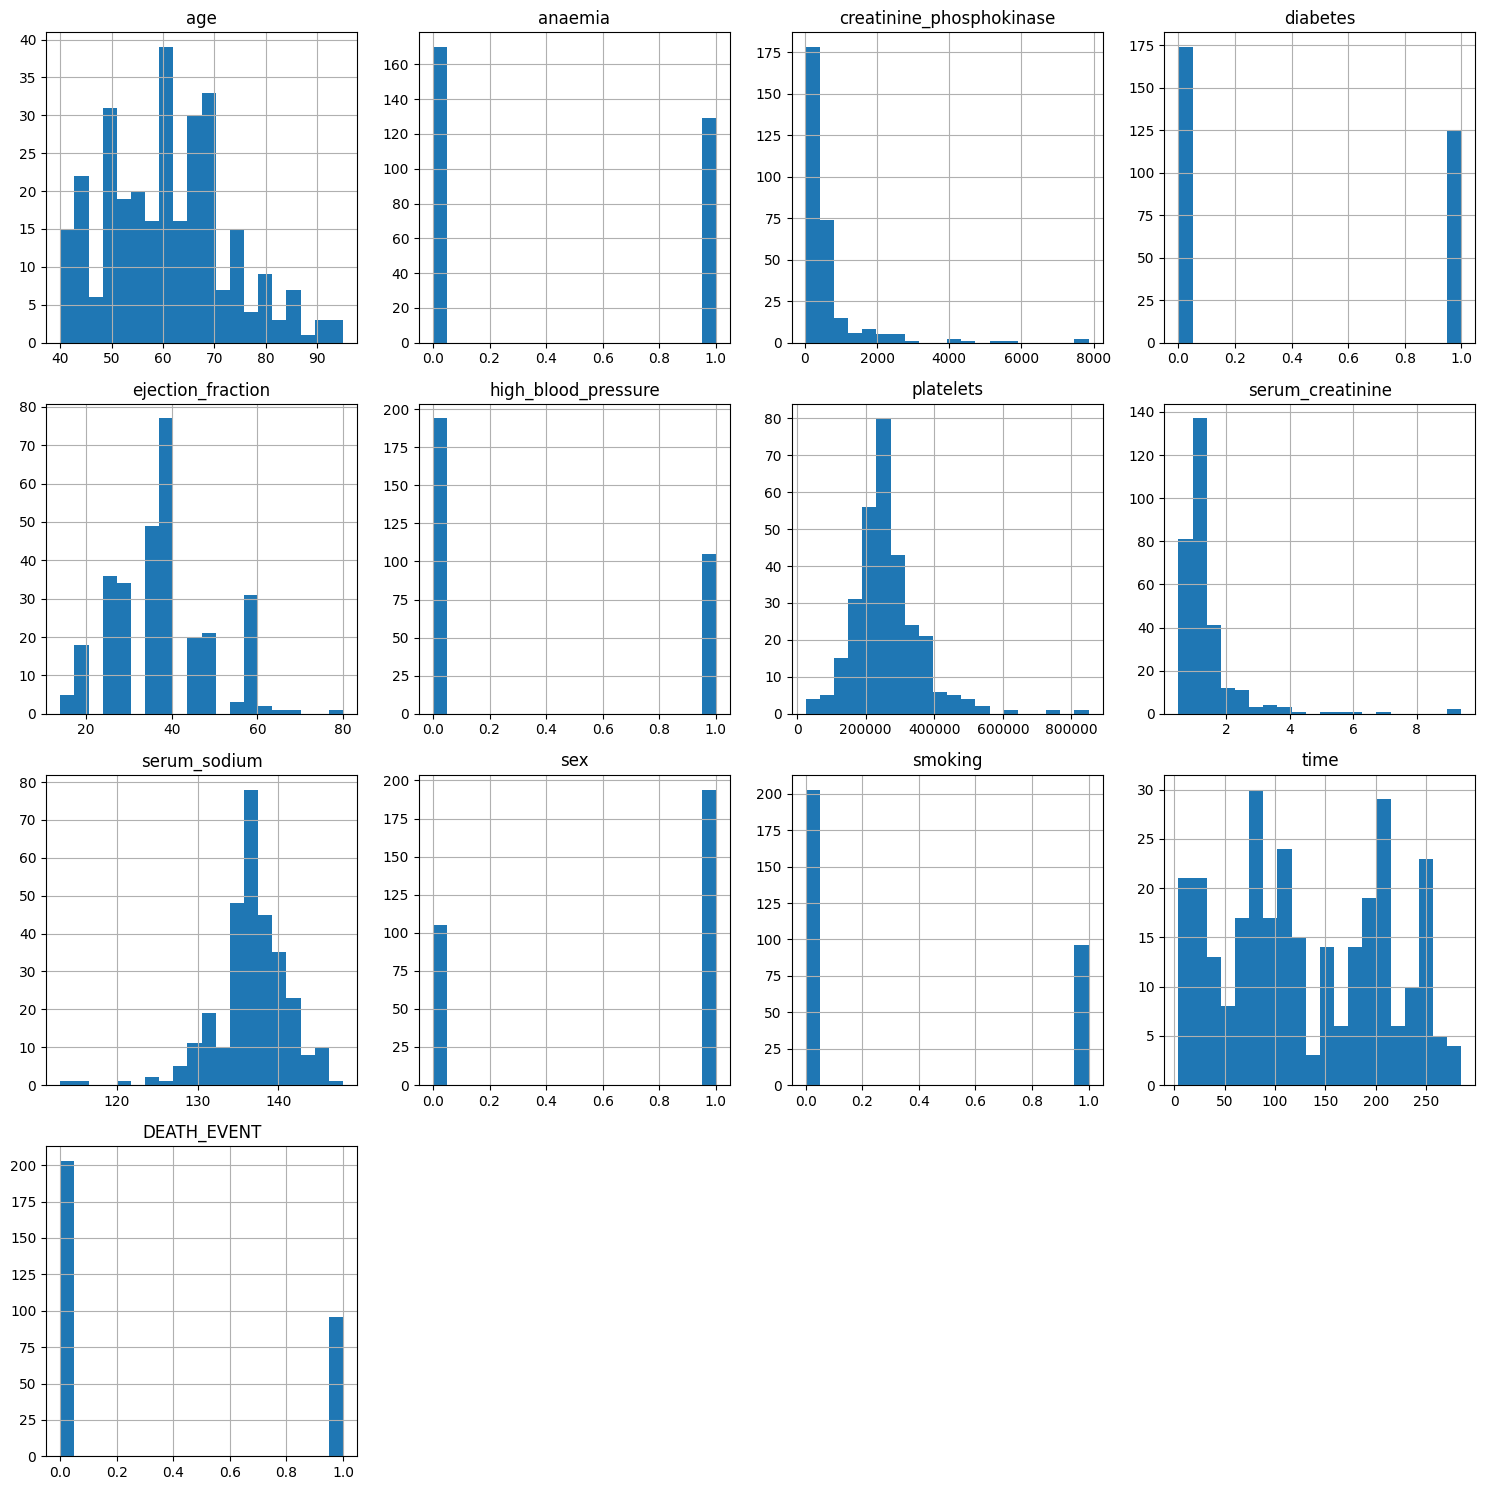

,count
DEATH_EVENT,
0,203
1,96


In [20]:
from numpy import binary_repr
### Question 1

## 1.1: Explore the heart_failure data set and clean it appropriately
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('heart_failure_clinical_records_dataset.csv')
print(df.shape)
print(df.dtypes)
df.info()
df.head()

# Check for missing values = 0
print(df.isnull().sum())

# Check for duplicate rows = 0
print(df.duplicated().sum())

# Check that binary variables are properly coded
print(df['anaemia'].unique())
print(df['diabetes'].unique())
print(df['high_blood_pressure'].unique())
print(df['smoking'].unique())
print(df['sex'].unique())
print(df['DEATH_EVENT'].unique())

# Look at data visualizations
df.hist(figsize = (15, 15), bins=20)
plt.tight_layout()
plt.show()

# Look at response variable
df['DEATH_EVENT'].value_counts()

# The dataset contains 299 observations and 13 numerical variables. There are no missing variables and all
# of the binary variables are correctly coded. No additional data cleaning was needed.


In [30]:
### Question 2

## 2.1: Perform a train-test split for a specific seed (save the seed for reproducibility)
from sklearn.model_selection import train_test_split

y = df['DEATH_EVENT']
X = df.drop(columns=['DEATH_EVENT', 'time'])

seed = 100

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

## 2.2/2.3: Fit a tree on the training data
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=seed).fit(X_train, y_train)

## 2.4/2.5: Fit a linear model on the training data
from sklearn.linear_model import LinearRegression

linear = LinearRegression().fit(X_train, y_train)
print('Intercept:', linear.intercept_)
pd.Series(linear.coef_, index=X_train.columns)

## 2.6: Evaluate performance on the test data (set aside predictions)
y_pred_tree = tree.predict(X_test)
y_pred_linear = linear.predict(X_test)

print('Tree Accuracy:', tree.score(X_test, y_test))
print('Linear Model R^2:', linear.score(X_test, y_test))

# The decision tree correctly classified 65% of the test observations. The linear model had an R^2 of roughly 0.137 which means
# it explains about 13.7% of the variation in the response variable in the test data.



Intercept: 1.2264567920720628
Tree Accuracy: 0.65
Linear Model R^2: 0.13683194590903713


In [39]:
### Question 3

## 3.1: Repeat step 2 for three to five different seeds (save the seeds for reproducibility).
# most efficient way is thru loop
seeds = [100, 200, 300, 400, 500]
trees = []
linear_models = []
tree_preds = []
linear_preds = []

for s in seeds: # train-test split
    X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
        X, y, test_size=0.2, random_state=s
    )
    # fitting models
    tree_new = DecisionTreeClassifier(random_state=s).fit(X_train_new, y_train_new)
    linear_new = LinearRegression().fit(X_train_new, y_train_new)

    # eval performance
    print('Seed:', s)
    print('Tree Accuracy:', tree_new.score(X_test_new, y_test_new))
    print('Linear Model R^2:', linear_new.score(X_test_new, y_test_new))
    print()

    # save models and preds
    trees.append(tree_new)
    linear_models.append(linear_new)
    tree_preds.append(tree_new.predict(X_test))
    linear_preds.append(linear_new.predict(X_test))


# 3.2: How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
# compare trees
for i in range(len(seeds)):
    print('Seed:', seeds[i])
    print('Depth:', trees[i].get_depth())
    print('Leaves:', trees[i].get_n_leaves())
    print()

# compare linear model coeffs
coeffs = pd.DataFrame(index=X.columns)
for i in range(len(seeds)):
    coeffs[seeds[i]] = linear_models[i].coef_
coeffs.round(4)

# The decision trees varied across the different train-test splits with depths ranging from 11 to 13 and the number of
# leaves ranging from 46 to 53. This suggests that the tree structures are somewhat sensitive to changes in the training
# data. In comparison, many of the linear model coefficients remained pretty consistent, especially for age, ejection fraction,
# and serum creatinine. However, some coefficients like anaemia, diabetes, and smoking varied more with diabetes and smoking
# changing signs across seeds. Overall, the linear models appear more stable in their coefficients, while decision trees
# show greater structural variation.


Seed: 100
Tree Accuracy: 0.65
Linear Model R^2: 0.13683194590903713

Seed: 200
Tree Accuracy: 0.7
Linear Model R^2: 0.00456473919034639

Seed: 300
Tree Accuracy: 0.7166666666666667
Linear Model R^2: 0.23887118988120393

Seed: 400
Tree Accuracy: 0.7666666666666667
Linear Model R^2: 0.2193570335494408

Seed: 500
Tree Accuracy: 0.7166666666666667
Linear Model R^2: -0.02546605503287558

Seed: 100
Depth: 13
Leaves: 52

Seed: 200
Depth: 13
Leaves: 46

Seed: 300
Depth: 12
Leaves: 51

Seed: 400
Depth: 11
Leaves: 51

Seed: 500
Depth: 12
Leaves: 53



,100,200,300,400,500
age,0.0097,0.0104,0.0097,0.0083,0.0092
anaemia,0.0061,0.0652,0.0900,0.0348,0.1107
creatinine_phosphokinase,0.0000,0.0001,0.0000,0.0001,0.0000
diabetes,0.0163,-0.0078,-0.0208,0.0262,0.0449
ejection_fraction,-0.0125,-0.0109,-0.0110,-0.0098,-0.0111
high_blood_pressure,0.0685,0.0439,0.0247,0.0318,0.0605
platelets,-0.0000,-0.0000,0.0000,0.0000,0.0000
serum_creatinine,0.0982,0.0998,0.0845,0.1069,0.1042
serum_sodium,-0.0084,-0.0156,-0.0090,-0.0119,-0.0153
sex,-0.0783,-0.0838,-0.0765,-0.0215,-0.0572


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]